In [1]:
pip install numpy pandas scipy scikit-learn matplotlib seaborn shap jupyter

Note: you may need to restart the kernel to use updated packages.


c:\Users\parth.DESKTOP-5935\Desktop\Work\Pandas\Battery_Claude_V2\.venv\Scripts\python.exe: No module named pip


In [2]:
import numpy as np
import pandas as pd
from scipy.io import loadmat
import datetime
import matplotlib.pyplot as plt
import seaborn as sns

### Load Dataset

In [3]:
def load_battery_file(battery):
    """Loading different battery files according to the battery name"""
    mat = loadmat(f"../data/{battery}.mat")
    cntr = 0
    dataset = []
    capacity_data = []

    for i in range(len(mat[battery][0][0]['cycle'][0])):
        row = mat[battery][0][0]['cycle'][0][i]
        if row['type'][0] == 'discharge':
            ambient_temperature = row['ambient_temperature'][0][0]
            date_time = datetime.datetime(int (row['time'][0][0]), 
                                          int(row['time'][0][1]), 
                                          int(row['time'][0][2]), 
                                          int(row['time'][0][3]), 
                                          int(row['time'][0][4]), 
                                          int(row['time'][0][5]))

            data = row['data']
            capacity = data[0][0]['Capacity'][0][0]
            for j in range(len(data[0][0]['Voltage_measured'][0])):
                voltage_measured = data[0][0]['Voltage_measured'][0][j]
                current_measured = data[0][0]['Current_measured'][0][j]
                temperature_measured = data[0][0]['Temperature_measured'][0][j]
                current_load = data[0][0]['Current_load'][0][j]
                voltage_load = data[0][0]['Voltage_load'][0][j]
                time = data[0][0]['Time'][0][j]

                dataset.append([cntr + 1, ambient_temperature, date_time, capacity, voltage_measured, current_measured, temperature_measured, current_load, voltage_load, time])

            capacity_data.append([cntr + 1, ambient_temperature, date_time, capacity])
            cntr += 1

    return [pd.DataFrame(data=dataset,
                       columns=['cycle', 'ambient_temperature', 'datetime',
                                'capacity', 'voltage_measured',
                                'current_measured', 'temperature_measured',
                                'current_load', 'voltage_load', 'time']),
          pd.DataFrame(data=capacity_data,
                       columns=['cycle', 'ambient_temperature', 'datetime',
                                'capacity'])]


print("Loading battery data...")
print("===========================================================================================================================================================")
pd.set_option('display.width', 200)
df = load_battery_file("B0005")[0]
print(df.head())
print("===========================================================================================================================================================")

Loading battery data...
   cycle  ambient_temperature            datetime  capacity  voltage_measured  current_measured  temperature_measured  current_load  voltage_load    time
0      1                   24 2008-04-02 15:25:41  1.856487          4.191492         -0.004902             24.330034       -0.0006         0.000   0.000
1      1                   24 2008-04-02 15:25:41  1.856487          4.190749         -0.001478             24.325993       -0.0006         4.206  16.781
2      1                   24 2008-04-02 15:25:41  1.856487          3.974871         -2.012528             24.389085       -1.9982         3.062  35.703
3      1                   24 2008-04-02 15:25:41  1.856487          3.951717         -2.013979             24.544752       -1.9982         3.030  53.781
4      1                   24 2008-04-02 15:25:41  1.856487          3.934352         -2.011144             24.731385       -1.9982         3.011  71.922


In [4]:
df1 = load_battery_file("B0005")[0]
df2 = load_battery_file("B0006")[0]
df3 = load_battery_file("B0007")[0]
df4 = load_battery_file("B0018")[0]

df1['battery_id'] = 'B0005'
df2['battery_id'] = 'B0006'
df3['battery_id'] = 'B0007'
df4['battery_id'] = 'B0018'

all_df = pd.concat([df1, df2, df3, df4], ignore_index=True)

all_cycle_df = all_df.groupby(['battery_id', 'cycle']).agg(
    capacity=('capacity', 'mean'),
    voltage_mean=('voltage_measured', 'mean'),
    voltage_min=('voltage_measured', 'min'),
    voltage_max=('voltage_measured', 'max'),
    voltage_std=('voltage_measured', 'std'),

    current_mean=('current_measured', 'mean'),
    current_min=('current_measured', 'min'),
    current_max=('current_measured', 'max'),
    current_std=('current_measured', 'std'),

    temperature_mean=('temperature_measured', 'mean'),
    temperature_min=('temperature_measured', 'min'),
    temperature_max=('temperature_measured', 'max'),
    temperature_std=('temperature_measured', 'std'),

    current_load_mean=('current_load', 'mean'),
    voltage_load_mean=('voltage_load', 'mean'),

    duration=('time', 'max')).reset_index()

print(all_cycle_df.shape)

(636, 18)


In [5]:
# ============================================================
# Extra per-cycle features: voltage discharge slope + incremental
# capacity (IC / dQ-dV) curve summary.
#
# These need the RAW within-cycle samples (all_df: one row per timestep),
# not the already-aggregated all_cycle_df - that's why this runs here,
# before anything gets collapsed to per-cycle means/stds.
# ============================================================

def compute_extra_cycle_features(group):
    """One (battery_id, cycle) discharge segment in -> slope + IC peak features out."""
    g = group.sort_values('time')
    t = g['time'].values
    v = g['voltage_measured'].values
    i = g['current_measured'].values

    # --- Voltage discharge slope (V per second). Steeper (more negative)
    # slope late in life is a known early-warning sign of degradation. ---
    if len(t) >= 2 and (t[-1] - t[0]) != 0:
        voltage_slope = np.polyfit(t, v, 1)[0]
    else:
        voltage_slope = np.nan

    # --- Incremental capacity curve: dQ/dV ---
    # Q(t) = cumulative discharged capacity in Ah. current_measured is
    # negative during discharge, so we integrate |current|.
    if len(t) >= 6:
        q = np.concatenate(([0.0], np.cumsum(np.abs(i[1:]) * np.diff(t) / 3600.0)))
        dv = np.diff(v)
        dq = np.diff(q)
        # Only keep points with a real voltage change (avoid divide-by-~0 spikes)
        valid = np.abs(dv) > 1e-4
        if valid.sum() >= 5:
            ic = dq[valid] / dv[valid]
            peak_idx = np.nanargmax(np.abs(ic))
            ic_peak_height = np.abs(ic[peak_idx])
            ic_peak_voltage = v[1:][valid][peak_idx]
        else:
            ic_peak_height, ic_peak_voltage = np.nan, np.nan
    else:
        ic_peak_height, ic_peak_voltage = np.nan, np.nan

    return pd.Series({
        'voltage_slope': voltage_slope,
        'ic_peak_height': ic_peak_height,
        'ic_peak_voltage': ic_peak_voltage
    })

extra_features = (
    all_df.groupby(['battery_id', 'cycle'])
    .apply(compute_extra_cycle_features)
    .reset_index()
)

all_cycle_df = all_cycle_df.merge(extra_features, on=['battery_id', 'cycle'], how='left')

print(all_cycle_df.shape)
print(f"NaN voltage_slope: {all_cycle_df['voltage_slope'].isna().sum()}")
print(f"NaN ic_peak_height: {all_cycle_df['ic_peak_height'].isna().sum()}")
all_cycle_df.head()

(636, 21)
NaN voltage_slope: 0
NaN ic_peak_height: 0


,battery_id,cycle,capacity,voltage_mean,voltage_min,voltage_max,voltage_std,current_mean,current_min,current_max,...,temperature_mean,temperature_min,temperature_max,temperature_std,current_load_mean,voltage_load_mean,duration,voltage_slope,ic_peak_height,ic_peak_voltage
0,B0005,1,1.856487,3.529829,2.612467,4.191492,0.236558,-1.818702,-2.018015,0.000729,...,32.572328,24.325993,38.982181,3.495804,-1.805570,2.404944,3690.234,-0.000206,6.351944,3.479329
1,B0005,2,1.846327,3.537320,2.587209,4.189773,0.235366,-1.817560,-2.016821,0.002927,...,32.725235,24.685948,39.033398,3.435509,-1.804583,2.399260,3672.344,-0.000205,6.781573,3.500066
2,B0005,3,1.835349,3.543737,2.651917,4.188187,0.228111,-1.816487,-2.016574,0.001484,...,32.642862,24.734266,38.818797,3.388174,-1.803575,2.397969,3651.641,-0.000200,6.854167,3.482607
3,B0005,4,1.835263,3.543666,2.592948,4.188461,0.233347,-1.825589,-2.015936,0.001547,...,32.514876,24.652244,38.762305,3.395306,-1.812863,2.408289,3631.563,-0.000205,6.988207,3.496433
4,B0005,5,1.834646,3.542343,2.547420,4.188299,0.237301,-1.826114,-2.017426,0.001701,...,32.382349,24.518700,38.665393,3.404667,-1.812876,2.408505,3629.172,-0.000208,6.098681,3.510383


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50285 entries, 0 to 50284
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   cycle                 50285 non-null  int64         
 1   ambient_temperature   50285 non-null  uint8         
 2   datetime              50285 non-null  datetime64[us]
 3   capacity              50285 non-null  float64       
 4   voltage_measured      50285 non-null  float64       
 5   current_measured      50285 non-null  float64       
 6   temperature_measured  50285 non-null  float64       
 7   current_load          50285 non-null  float64       
 8   voltage_load          50285 non-null  float64       
 9   time                  50285 non-null  float64       
dtypes: datetime64[us](1), float64(7), int64(1), uint8(1)
memory usage: 3.5 MB


In [7]:
df.describe() # no missing data present in any columns.

,cycle,ambient_temperature,datetime,capacity,voltage_measured,current_measured,temperature_measured,current_load,voltage_load,time
count,50285.000000,50285.0,50285,50285.000000,50285.000000,50285.000000,50285.000000,50285.000000,50285.000000,50285.000000
mean,88.125942,24.0,2008-05-07 01:58:43.570826,1.560345,3.515268,-1.806032,32.816991,1.362700,2.308406,1546.208924
min,1.000000,24.0,2008-04-02 15:25:41,1.287453,2.455679,-2.029098,23.214802,-1.998400,0.000000,0.000000
25%,50.000000,24.0,2008-04-29 22:00:04,1.386229,3.399384,-2.013415,30.019392,1.998000,2.388000,768.563000
50%,88.000000,24.0,2008-05-07 21:56:09,1.538237,3.511664,-2.012312,32.828944,1.998200,2.533000,1537.031000
75%,127.000000,24.0,2008-05-18 03:05:19,1.746871,3.660903,-2.011052,35.920887,1.998200,2.690000,2305.984000
max,168.000000,24.0,2008-05-27 20:45:42,1.856487,4.222920,0.007496,41.450232,1.998400,4.238000,3690.234000
std,45.699687,0.0,NaN,0.182380,0.231778,0.610502,3.987515,1.313698,0.800300,906.640295


### Exploratory Data Analysis (EDA)

In [8]:
pip install pypalettes

Note: you may need to restart the kernel to use updated packages.


c:\Users\parth.DESKTOP-5935\Desktop\Work\Pandas\Battery_Claude_V2\.venv\Scripts\python.exe: No module named pip


Text(0, 0.5, 'Average Capacity')

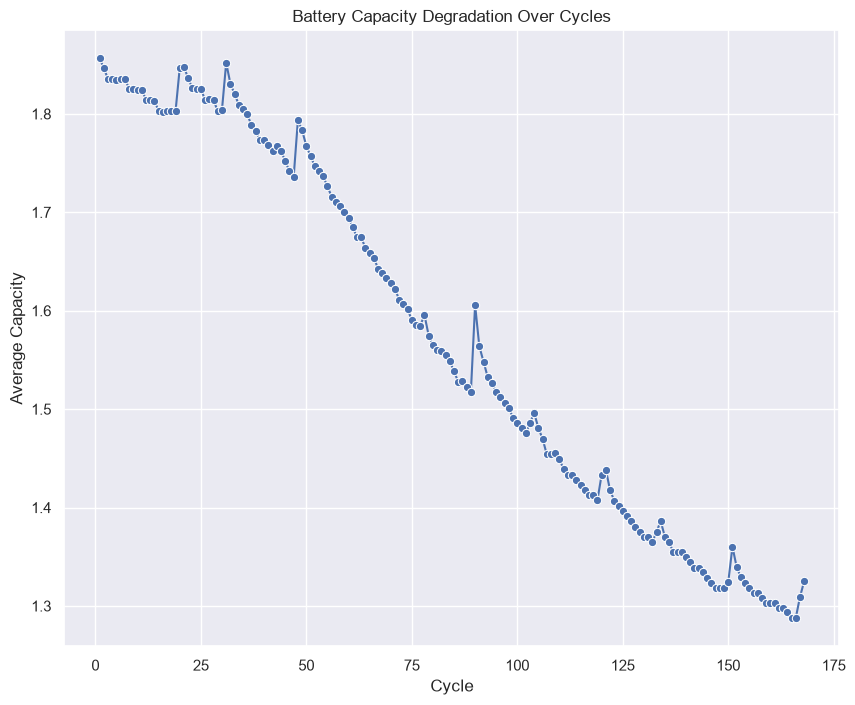

In [9]:
'''
from pypalettes import load_palette

palette = load_palette("xmen")
sns.barplot(y = 'capacity', x = 'current_measured', data=df)
sns.set_theme(style="darkgrid")
sns.boxplot(x='capacity', y = 'cycle', data=df, palette=palette)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='cycle', y='capacity')'''

cycle_capacity = df.groupby('cycle')['capacity'].mean().reset_index()

plt.figure(figsize=(10, 8))
sns.set_theme(style="darkgrid")
sns.lineplot(
    data=cycle_capacity,
    x='cycle',
    y='capacity',
    marker='o'
)

plt.title('Battery Capacity Degradation Over Cycles')
plt.xlabel('Cycle')
plt.ylabel('Average Capacity')

Text(0.5, 1.0, 'Histogram of Capacity')

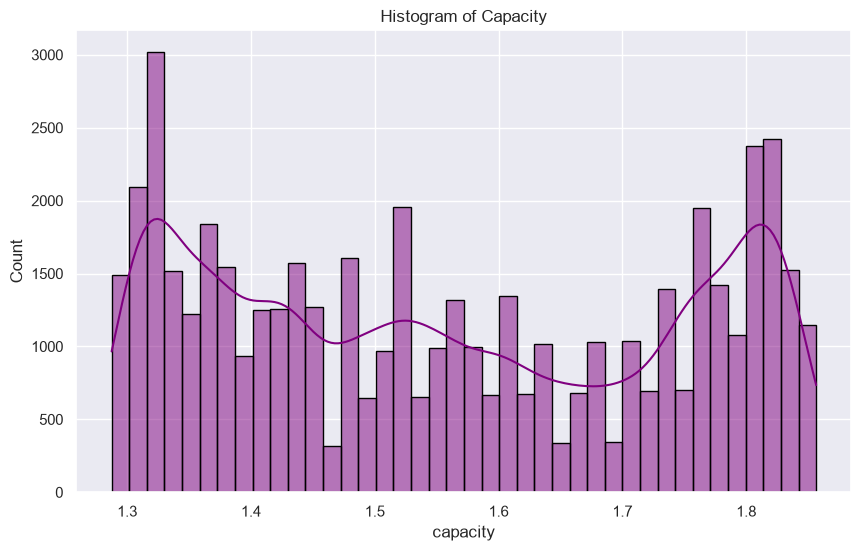

In [10]:
plt.figure(figsize=(10, 6))
sns.histplot(x='capacity', data=df, bins=40, kde=True, color='purple', edgecolor='black', alpha=0.5)
plt.title("Histogram of Capacity")

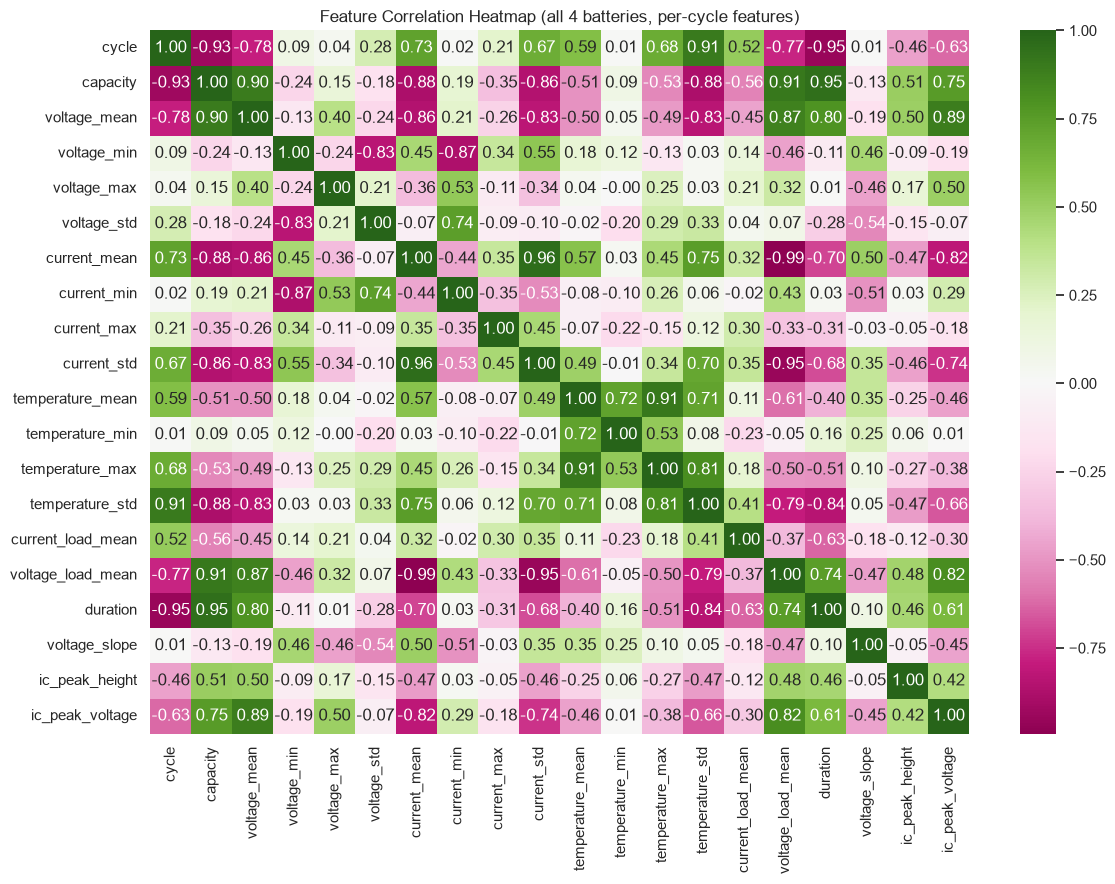

In [11]:
plt.figure(figsize=(12, 9))
numeric_cols = all_cycle_df.select_dtypes(include=[np.number]).columns
sns.heatmap(all_cycle_df[numeric_cols].corr(), annot=True, cmap='PiYG', fmt=".2f")
plt.title('Feature Correlation Heatmap (all 4 batteries, per-cycle features)')
plt.tight_layout()
plt.show()

### Electrical Behaviors, Degradations & Measurements

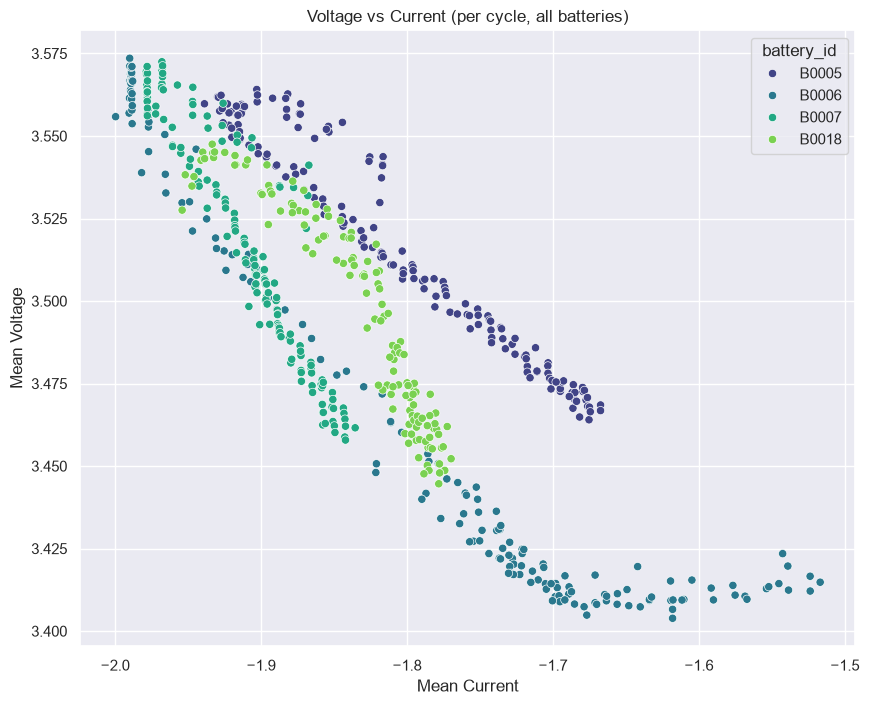

In [12]:
plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=all_cycle_df,
    x='current_mean',
    y='voltage_mean',
    hue='battery_id',
    palette='viridis'
)

plt.title('Voltage vs Current (per cycle, all batteries)')
plt.xlabel('Mean Current')
plt.ylabel('Mean Voltage')
plt.show()

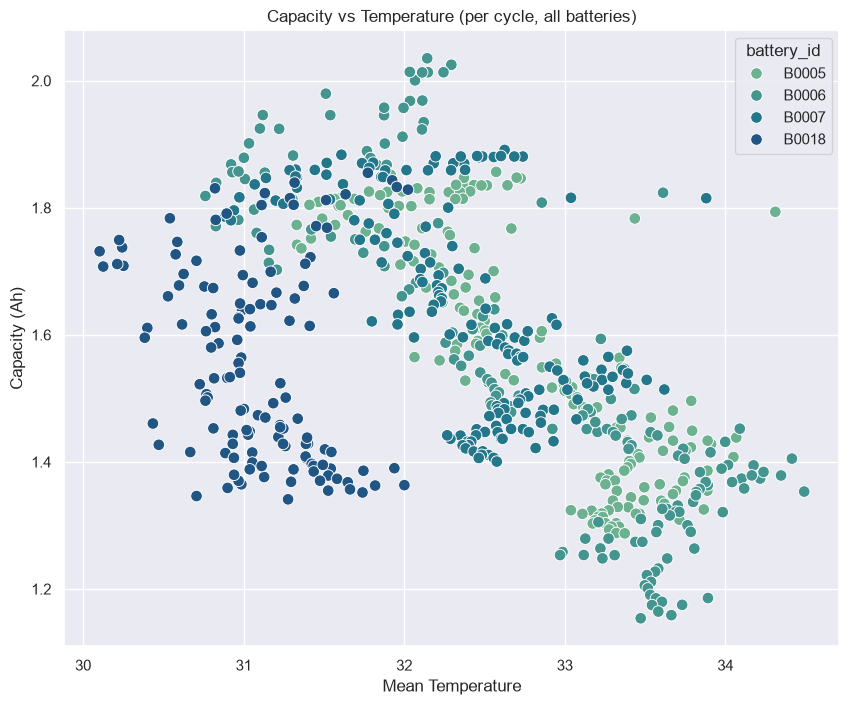

In [13]:
plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=all_cycle_df,
    x='temperature_mean',
    y='capacity',
    s=70,
    hue='battery_id',
    palette='crest'
)

plt.title('Capacity vs Temperature (per cycle, all batteries)')
plt.xlabel('Mean Temperature')
plt.ylabel('Capacity (Ah)')
plt.show()

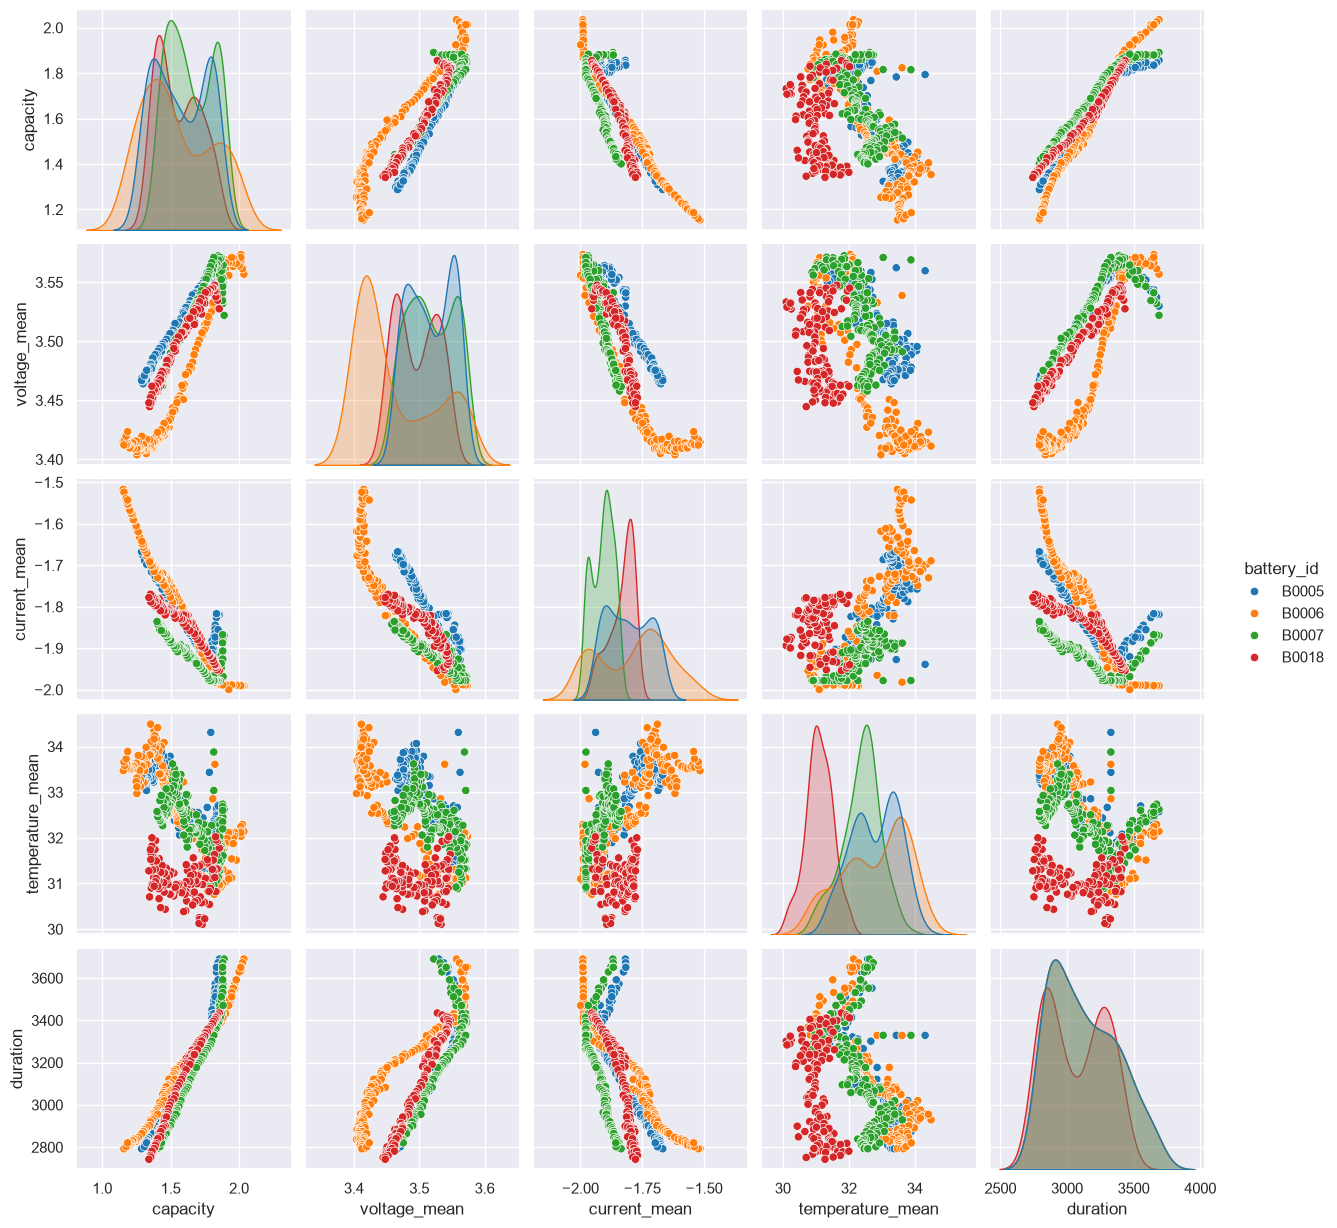

In [14]:
plot_cols = ['capacity', 'voltage_mean', 'current_mean', 'temperature_mean', 'duration', 'battery_id']

sns.pairplot(all_cycle_df[plot_cols], hue='battery_id', palette='tab10', diag_kind='kde')
plt.show()

In [15]:
all_cycle_df.to_csv("../src/battery_cycle_data.csv", index=False)